# Performance evaluation for **XenofilteR**

In this notebook, we evaluate the read-sorting performance of XenofilteR for whole-genome bisulfite mouse/human in silico mixtures. 

We used two different parameter settings to run XenofilteR:
- MM_Threshold = 4 (default)
- MM_Threshold = 8, which is preferred for longer reads (e.g. 100bp or 150bp)

XenofilteR performs xenograft-sorting by only retaining human-classified reads by using a dual-alignment approach. The remaining reads are discarded. 

## 0. Imports and path assignments

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay
import sys
import os
sys.path.append(os.path.abspath(os.path.join("..")))
from helper.visualization import *
from helper.metrics import * 

from warnings import simplefilter
simplefilter("ignore")

In [ ]:
data_dir = Path("/omics/groups/OE0219/internal/altendorfer/epiproper/read_sorting_benchmark/data")
method = "xenofilter"
fig_dir = Path.cwd() / "figures" / method
fig_dir.mkdir(exist_ok=True, parents=True)

## 1. Load data

In [3]:
df = read_evaluations(data_dir, method)
df_mm8 = read_evaluations(data_dir, "xenofilter_mm8").drop_duplicates()

In [4]:
df["Human_Ratio"] = [float(s.rstrip('p')) for s in df["Mixture"] ]
df_mm8["Human_Ratio"] = [float(s.rstrip('p')) for s in df_mm8["Mixture"] ]

## 2. Confusion Matrix

In [5]:
df_conf = assign_confusion_matrix(df, method="xenofilter")
df_conf_mm8 = assign_confusion_matrix(df_mm8, method="xenofilter")

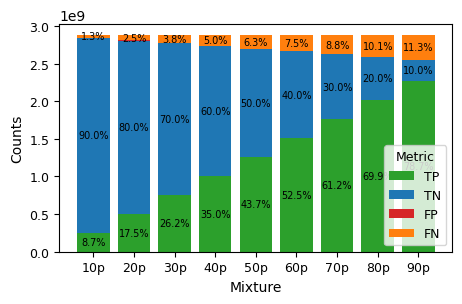

In [6]:
figsize = mm_to_inches((120, 80))
plot_stacked_confusion_bar(
    df_conf,
    save=False,
    figsize= figsize,
)

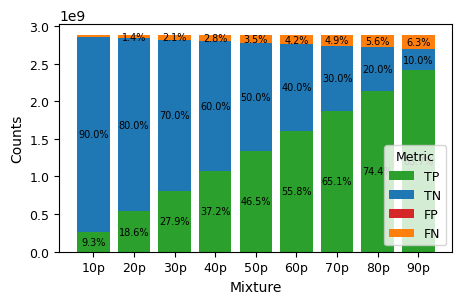

In [8]:
plot_stacked_confusion_bar(
    df_conf_mm8,
    save=False,
    figsize= figsize)

Xenofilter with MM_Threshold=8 outperforms the default configuration due to less human read loss (false negatives).

From now on, we will only analyze xenofilter_mm8.

## 3. Calculate performance metrics

In [9]:
df_metrics = calculate_metrics(df_conf_mm8)

## 4. Save DataFrame

In [20]:
df_metrics["Method"] = "XenofilteR"
out_dir = Path.cwd() / "results"
out_dir.mkdir(exist_ok=True)

df_metrics.to_csv(out_dir / "xenofilter.csv", index=False)